# 🧠 AURORA RESEARCH LAB — Bootstrap v2.0

## Topological Surface Metrology + Number Theory

**Mission**: Discover new measurable invariants in mathematical surfaces derived from arithmetic systems.

**Core principle**: All mathematical objects are treated as physical-like surfaces. Every claim must be measurable, falsifiable, and numerically testable against null models.

---

### Bootstrap Protocol

1. Generate primes (N = 10⁵) and zeta zeros (n = 10³)
2. Construct arithmetic surfaces (binary, gap, density, spectral)
3. Build null-model surfaces (Gaussian, Poisson, 1/f, Brownian, Bernoulli)
4. Compute ISO-style surface metrology
5. Quantify deviations → generate & test hypotheses
6. Adversarial review → ranked surviving invariants

## 1. Setup & Imports

In [1]:
# ══════════════════════════════════════════════════════════════
# AURORA RESEARCH LAB — Bootstrap v2.0
# ══════════════════════════════════════════════════════════════

import sys, os, time, json, warnings, zlib
from datetime import datetime
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from scipy import stats, signal
from scipy.fft import fft, fftfreq
from scipy.ndimage import gaussian_filter1d

warnings.filterwarnings("ignore")

# Ensure aurora_lab is importable
WORKSPACE = Path.cwd()
if str(WORKSPACE) not in sys.path:
    sys.path.insert(0, str(WORKSPACE))

from aurora_lab import config
from aurora_lab.core import (
    generate_primes, prime_gaps, prime_density,
    get_zeta_zeros, zeta_on_critical_line,
)
from aurora_lab.surfaces import (
    Surface,
    binary_prime_surface, prime_gap_surface, prime_density_surface,
    zeta_spectral_surface, zeta_smoothed_density, zeta_modulus_surface,
    build_all_surfaces,
)
from aurora_lab.null_models import (
    gaussian_random_surface, poisson_surface,
    one_over_f_surface, brownian_surface,
    bernoulli_surface, generate_all_null_models,
)
from aurora_lab.metrology import (
    MetrologyReport,
    compute_roughness, compute_autocorrelation, compute_spectral,
    compute_fractal, compute_information,
    analyse_surface, analyse_all, deviation_summary,
)
from aurora_lab.reporting import (
    Hypothesis, BootstrapReport,
    format_report, metrics_dataframe,
    generate_initial_hypotheses,
)

print("✅ AURORA RESEARCH LAB — all modules loaded.")
print(f"   aurora_lab v{__import__('aurora_lab').__version__}")
print(f"   Workspace: {WORKSPACE}")
print(f"   Timestamp: {datetime.now().isoformat()}")

✅ AURORA RESEARCH LAB — all modules loaded.
   aurora_lab v2.0.0
   Workspace: /Users/dawid/Projects/interfero-Riemann
   Timestamp: 2026-06-08T16:41:26.571449


## 2. Data Generation — Primes & Zeta Zeros

**Step 1 of the bootstrap protocol**: generate the raw arithmetic data.

- Primes ≤ 10⁵ via sieve of Eratosthenes
- First 10³ zeta zeros (first 100 exact via mpmath, remainder via Riemann–von Mangoldt approximation)

In [2]:
# ── Generate primes ─────────────────────────────────────────────
PRIME_LIMIT = 100_000

t0 = time.time()
primes = generate_primes(PRIME_LIMIT)
t_primes = time.time() - t0

prime_density_val = len(primes) / PRIME_LIMIT
gaps = prime_gaps(primes)

print("══ Primes ══")
print(f"   Limit:       N = {PRIME_LIMIT:,}")
print(f"   π(N):        {len(primes):,}")
print(f"   Density:     {prime_density_val:.6f}")
print(f"   Max gap:     {gaps.max()}")
print(f"   Mean gap:    {gaps.mean():.4f}")
print(f"   Std gap:     {gaps.std():.4f}")
print(f"   Largest p:   {primes[-1]}")
print(f"   Time:        {t_primes:.3f} s")

# ── Get zeta zeros ─────────────────────────────────────────────
N_ZEROS = 1000
N_EXACT = 100

print("\n══ Zeta Zeros ══")
print(f"   Computing first {N_ZEROS} zeros ({N_EXACT} exact, rest approx)…")
t0 = time.time()
zeros = get_zeta_zeros(n_zeros=N_ZEROS, n_exact=N_EXACT)
t_zeros = time.time() - t0

zero_gaps = np.diff(zeros)
print(f"   γ₁:          {zeros[0]:.8f}")
print(f"   γ₁₀:         {zeros[9]:.8f}")
print(f"   γ₁₀₀:        {zeros[99]:.8f}")
print(f"   γ₁₀₀₀:       {zeros[-1]:.8f}")
print(f"   Mean spacing: {zero_gaps.mean():.6f}")
print(f"   Std spacing:  {zero_gaps.std():.6f}")
print(f"   Time:         {t_zeros:.3f} s")

# Store for later
dataset_info = {
    "prime_limit": PRIME_LIMIT,
    "n_primes": len(primes),
    "prime_density": prime_density_val,
    "max_prime_gap": int(gaps.max()),
    "n_zeta_zeros": N_ZEROS,
    "n_exact_zeros": N_EXACT,
    "zeta_zero_range": (float(zeros[0]), float(zeros[-1])),
    "computation_time_s": round(t_primes + t_zeros, 3),
}


══ Primes ══
   Limit:       N = 100,000
   π(N):        9,592
   Density:     0.095920
   Max gap:     72
   Mean gap:    10.4253
   Std gap:     8.0236
   Largest p:   99991
   Time:        0.002 s

══ Zeta Zeros ══
   Computing first 1000 zeros (100 exact, rest approx)…
   γ₁:          14.13472514
   γ₁₀:         49.77383248
   γ₁₀₀:        236.52422967
   γ₁₀₀₀:       1420.09735149
   Mean spacing: 1.407370
   Std spacing:  0.450336
   Time:         27.925 s


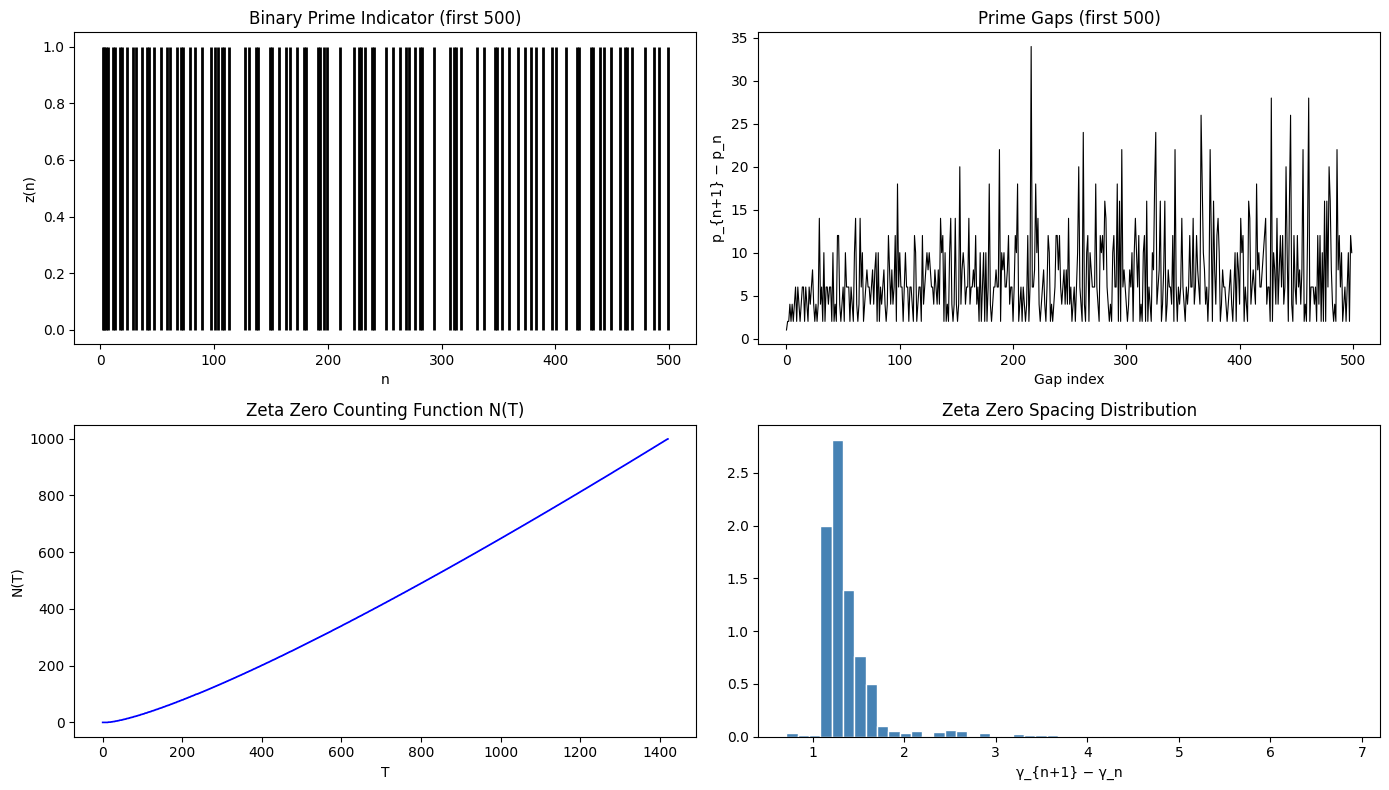

✅ Data overview saved to fig_data_overview.png


In [3]:
# Quick visual check
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Prime indicator (first 500 integers)
x500 = np.arange(1, 501)
is_prime_500 = np.isin(x500, primes).astype(int)
axes[0, 0].vlines(x500[is_prime_500 == 1], 0, 1, color="black", linewidth=2)
axes[0, 0].set_title("Binary Prime Indicator (first 500)")
axes[0, 0].set_xlabel("n"); axes[0, 0].set_ylabel("z(n)")

# Prime gaps
axes[0, 1].plot(gaps[:500], "k-", linewidth=0.8)
axes[0, 1].set_title("Prime Gaps (first 500)")
axes[0, 1].set_xlabel("Gap index"); axes[0, 1].set_ylabel("p_{n+1} − p_n")

# Zeta zeros: staircase N(T)
t_vals = np.linspace(0, zeros[-1], 2000)
N_T = np.searchsorted(zeros, t_vals)
axes[1, 0].plot(t_vals, N_T, "b-", linewidth=1.2)
axes[1, 0].set_title("Zeta Zero Counting Function N(T)")
axes[1, 0].set_xlabel("T"); axes[1, 0].set_ylabel("N(T)")

# Zero spacing distribution
axes[1, 1].hist(zero_gaps, bins=50, density=True, color="steelblue", edgecolor="white")
axes[1, 1].set_title("Zeta Zero Spacing Distribution")
axes[1, 1].set_xlabel("γ_{n+1} − γ_n")

plt.tight_layout()
plt.savefig(WORKSPACE / "fig_data_overview.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Data overview saved to fig_data_overview.png")

## 3. Surface Construction — Arithmetic → Topography

**Step 2 of the bootstrap protocol**: transform mathematical objects into 2D height‑field surfaces.

The 1D sequences are reshaped into square (or near‑square) 2D arrays to enable ISO 25178‑style areal surface metrology.

In [4]:
# Build all arithmetic surfaces
surfaces = build_all_surfaces(primes, zeros, PRIME_LIMIT)

# Summary
print("══ Arithmetic Surfaces Constructed ══\n")
for key, surf in surfaces.items():
    print(f"  [{key}]")
    print(f"       Name:        {surf.name}")
    print(f"       Shape:       {surf.shape}")
    print(f"       Size:        {surf.size:,}")
    print(f"       Mean height: {surf.height.mean():.4f}")
    print(f"       Std height:  {surf.height.std():.4f}")
    print(f"       Min/Max:     {surf.height.min():.4f} / {surf.height.max():.4f}")
    print()

══ Arithmetic Surfaces Constructed ══

  [binary_prime]
       Name:        Binary Prime Surface
       Shape:       (316, 316)
       Size:        99,856
       Mean height: 0.0959
       Std height:  0.2945
       Min/Max:     0.0000 / 1.0000

  [prime_gap]
       Name:        Prime Gap Surface
       Shape:       (30, 316)
       Size:        9,480
       Mean height: 10.4189
       Std height:  8.0248
       Min/Max:     1.0000 / 72.0000

  [prime_density]
       Name:        Prime Density Surface π(x)
       Shape:       (316, 316)
       Size:        99,856
       Mean height: 5041.5857
       Std height:  2702.8396
       Min/Max:     0.0000 / 9580.0000

  [zeta_spectral]
       Name:        Zeta Spectral Surface
       Shape:       (3, 316)
       Size:        948
       Mean height: 757.3382
       Std height:  369.7685
       Min/Max:     14.1347 / 1359.5813

  [zeta_smoothed]
       Name:        Zeta Smoothed Density Field
       Shape:       (316, 316)
       Size:        9

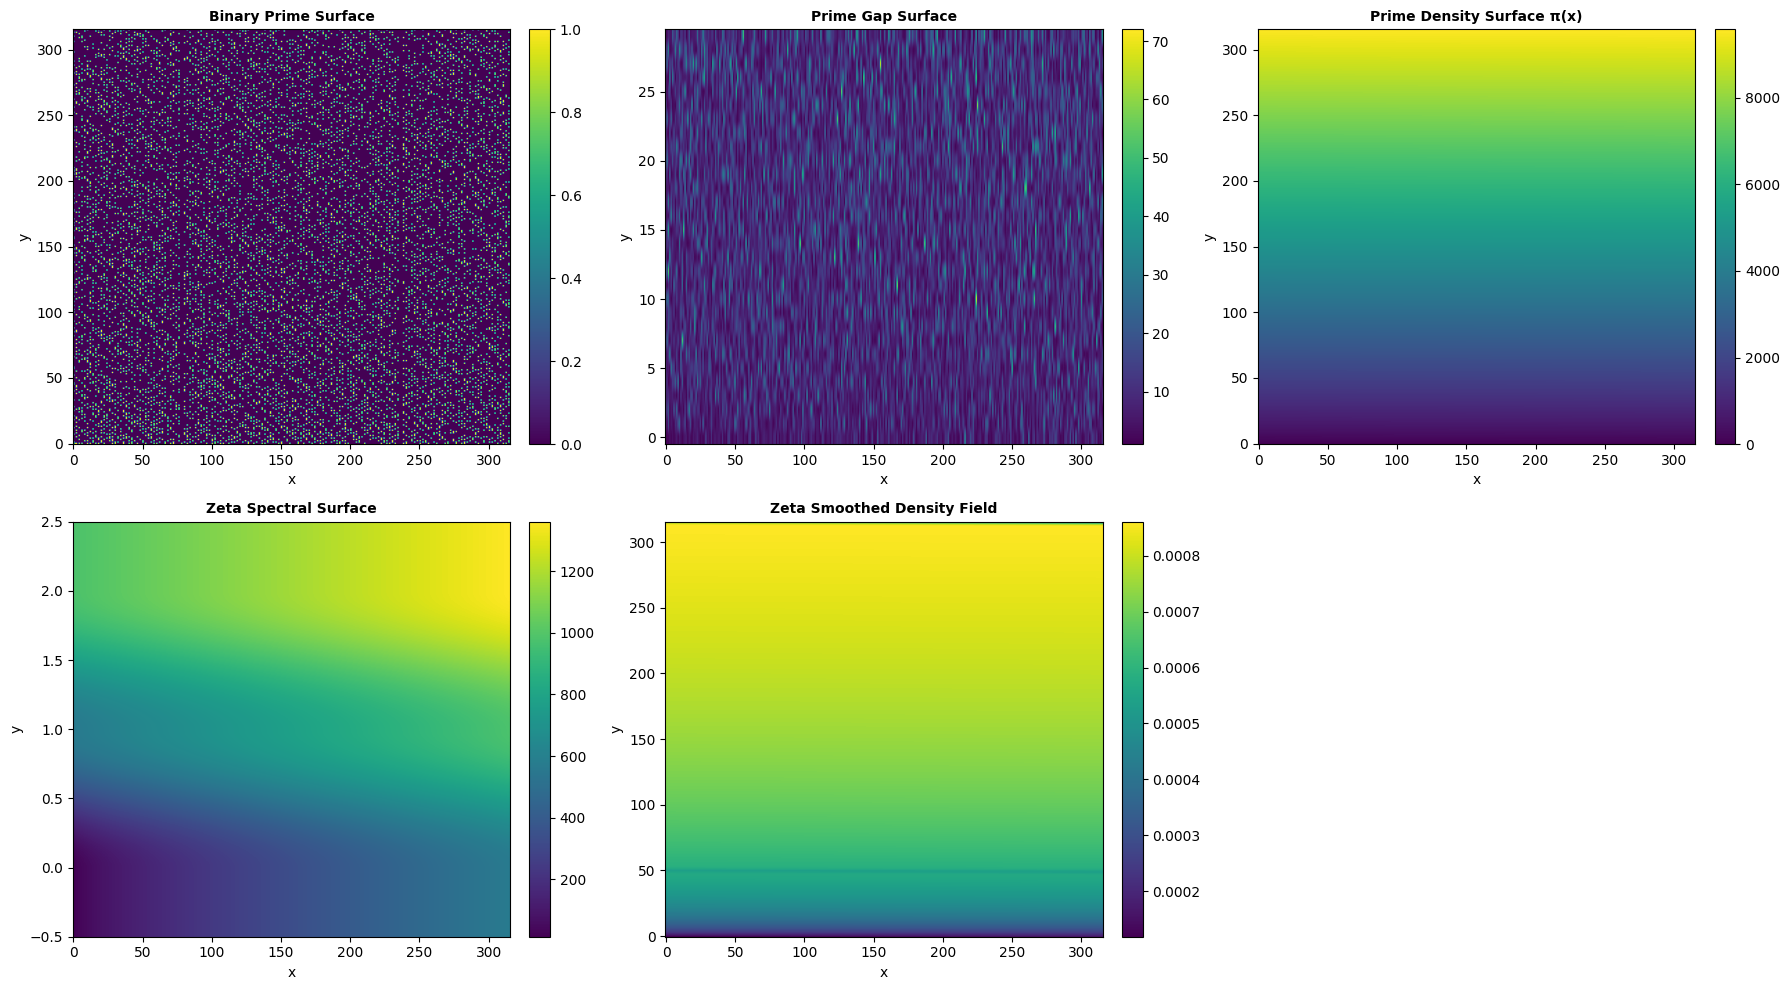

✅ Surface maps saved to fig_surfaces_2d.png


In [5]:
# Visualise all surfaces as 2D height maps
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for idx, (key, surf) in enumerate(surfaces.items()):
    if idx >= 6:
        break
    ax = axes[idx]
    im = ax.imshow(surf.height, aspect="auto", cmap="viridis", origin="lower")
    ax.set_title(surf.name, fontsize=10, weight="bold")
    ax.set_xlabel("x"); ax.set_ylabel("y")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

# Hide extra axes
for j in range(len(surfaces), 6):
    axes[j].set_visible(False)

plt.tight_layout()
plt.savefig(WORKSPACE / "fig_surfaces_2d.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Surface maps saved to fig_surfaces_2d.png")

## 4. Null-Model Surfaces

**Step 3 of the bootstrap protocol**: generate reference surfaces for hypothesis testing.

Each null model matches the shape of the corresponding arithmetic surface. We generate:
1. **Gaussian** — independent N(0,1) at each pixel (max entropy, zero correlation)
2. **Poisson** — Poisson(λ) at each pixel (sparse spike analogue)
3. **1/f noise** — pink noise, PSD ∝ 1/f (long-range correlated)
4. **Brownian** — integrated white noise, PSD ∝ 1/f² (non-stationary)
5. **Bernoulli** — independent binary at matched prime density (control for binary surface)

In [6]:
# Build null models matching each real surface's shape
# We also create ensembles (n=20) for robust statistics

N_ENSEMBLE = 20
rng = np.random.default_rng(config.RANDOM_SEED)

null_models = {}          # key → dict of null Surface objects
null_ensembles = {}       # key → dict of lists of MetrologyReport

for key, real_surf in surfaces.items():
    shape = real_surf.shape
    print(f"[{key}] shape={shape}")

    # Single representative null models
    null_models[key] = generate_all_null_models(
        shape,
        poisson_rate=0.01,
        bernoulli_p=prime_density_val,
    )

    # Ensemble for statistics (use only the most relevant null types)
    # Run metrology on all ensemble members — we'll do this later
    null_ensembles[key] = {
        "gaussian":  [gaussian_random_surface(shape) for _ in range(N_ENSEMBLE)],
        "poisson":   [poisson_surface(shape, rate=0.01) for _ in range(N_ENSEMBLE)],
        "one_over_f": [one_over_f_surface(shape) for _ in range(N_ENSEMBLE)],
        "brownian":  [brownian_surface(shape) for _ in range(N_ENSEMBLE)],
        "bernoulli": [bernoulli_surface(shape, p=prime_density_val) for _ in range(N_ENSEMBLE)],
    }
    print(f"   → {len(null_models[key])} null types × {N_ENSEMBLE} ensemble members")

print(f"\n✅ {len(null_models)} surface × {len(null_models[list(surfaces.keys())[0]])} null types ready.")

[binary_prime] shape=(316, 316)
   → 5 null types × 20 ensemble members
[prime_gap] shape=(30, 316)
   → 5 null types × 20 ensemble members
[prime_density] shape=(316, 316)
   → 5 null types × 20 ensemble members
[zeta_spectral] shape=(3, 316)
   → 5 null types × 20 ensemble members
[zeta_smoothed] shape=(316, 316)
   → 5 null types × 20 ensemble members

✅ 5 surface × 5 null types ready.


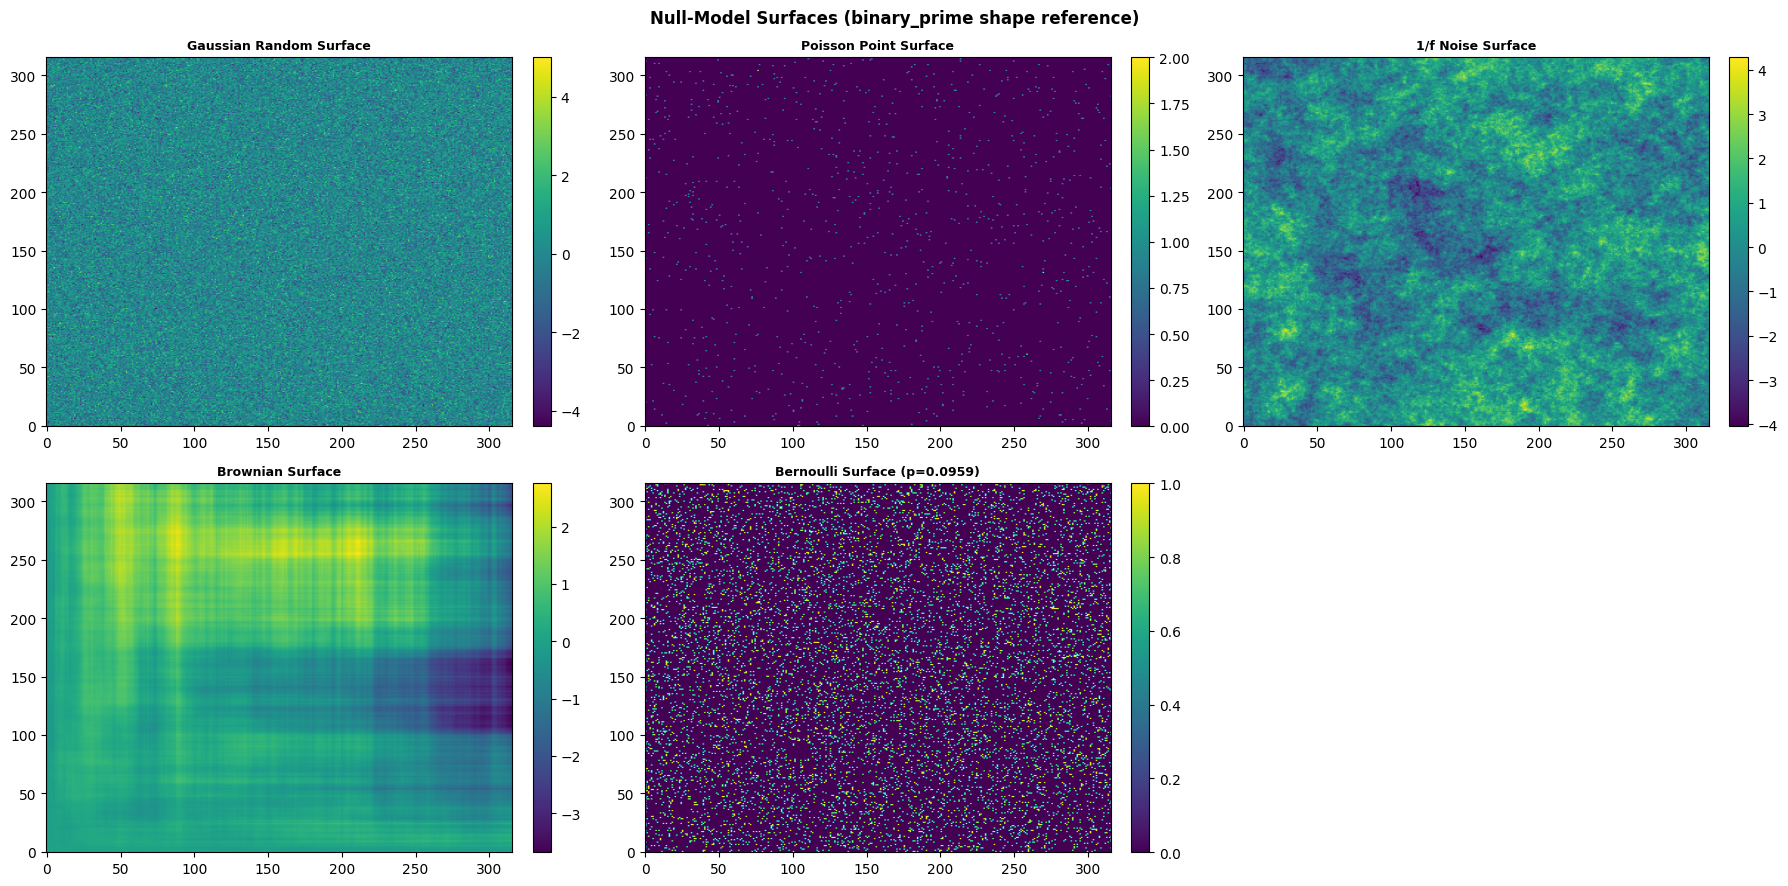

✅ Null-model maps saved to fig_null_models.png


In [7]:
# Visualise null models (using binary_prime shape as reference)
ref_shape = surfaces["binary_prime"].shape
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.ravel()

null_demo = null_models["binary_prime"]
for idx, (nkey, nsurf) in enumerate(null_demo.items()):
    if idx >= 5:
        break
    ax = axes[idx]
    im = ax.imshow(nsurf.height, aspect="auto", cmap="viridis", origin="lower")
    ax.set_title(nsurf.name, fontsize=9, weight="bold")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

axes[5].set_visible(False)
plt.suptitle("Null-Model Surfaces (binary_prime shape reference)", weight="bold")
plt.tight_layout()
plt.savefig(WORKSPACE / "fig_null_models.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Null-model maps saved to fig_null_models.png")

## 5. Surface Metrology — Roughness, Spectral, Fractal & Information

**Step 4 of the bootstrap protocol**: compute the full ISO‑style metrology on every real and null‑model surface.

Metrics computed:
- **Roughness**: Sa, Sq, Ssk, Sku, Sp, Sv, Sz, Sal, Str
- **Spectral**: 2D FFT power spectrum, radial PSD slope
- **Fractal**: box‑counting dimension D_f, lacunarity
- **Information**: Shannon entropy, compression ratio

In [8]:
# ── Run full metrology on all real surfaces ──────────────────────
print("══ Computing metrology on arithmetic surfaces… ══\n")
real_reports = analyse_all(surfaces)

for key, report in real_reports.items():
    print(f"  [{key}]")
    print(f"       Sa={report.Sa:.4f}  Sq={report.Sq:.4f}  "
          f"Ssk={report.Ssk:.4f}  Sku={report.Sku:.4f}")
    print(f"       Sp={report.Sp:.4f}  Sv={report.Sv:.4f}  Sz={report.Sz:.4f}")
    print(f"       Sal={report.Sal:.1f}  Str={report.Str:.4f}")
    print(f"       D_f={report.D_f:.4f}  Lac={report.lacunarity:.4f}")
    print(f"       H={report.shannon_entropy:.4f} bits  "
          f"CR={report.compression_ratio:.4f}  PSD_slope={report.psd_slope:.4f}")
    print()

# ── Run metrology on single null models ──────────────────────────
print("══ Computing metrology on null models… ══\n")
null_reports = {}  # key → {null_type → MetrologyReport}

for key, null_dict in null_models.items():
    null_reports[key] = {}
    for nkey, nsurf in null_dict.items():
        null_reports[key][nkey] = analyse_surface(nsurf)
    print(f"  [{key}] {len(null_dict)} null types done.")

# ── Run metrology on null ensembles (for robust z‑scores) ────────
print("\n══ Computing ensemble metrology (this takes a moment)… ══\n")
null_ensemble_reports = {}  # key → {null_type → [MetrologyReport × N_ENSEMBLE]}

for key, ensemble_dict in null_ensembles.items():
    null_ensemble_reports[key] = {}
    for nkey, surf_list in ensemble_dict.items():
        reports = [analyse_surface(s) for s in surf_list]
        null_ensemble_reports[key][nkey] = reports
    print(f"  [{key}] {len(ensemble_dict)} null types × {N_ENSEMBLE} done.")

print("\n✅ All metrology complete.")
print(f"   {len(real_reports)} real surfaces × "
      f"{len(null_models[list(surfaces.keys())[0]])} null types × "
      f"{N_ENSEMBLE} ensemble = "
      f"{len(real_reports) * len(null_models[list(surfaces.keys())[0]]) * N_ENSEMBLE} total reports")

══ Computing metrology on arithmetic surfaces… ══

  [binary_prime]
       Sa=0.1735  Sq=0.2945  Ssk=2.7440  Sku=8.5295
       Sp=0.9041  Sv=-0.0959  Sz=1.0000
       Sal=1.0  Str=1.0000
       D_f=1.9372  Lac=0.4016
       H=0.4560 bits  CR=0.9192  PSD_slope=0.1913

  [prime_gap]
       Sa=6.0377  Sq=8.0248  Ssk=1.6885  Sku=7.0520
       Sp=61.5811  Sv=-9.4189  Sz=71.0000
       Sal=1.0  Str=0.5000
       D_f=0.0000  Lac=0.0767
       H=3.5862 bits  CR=0.3646  PSD_slope=0.0725

  [prime_density]
       Sa=2332.9806  Sq=2702.8396  Ssk=-0.0855  Sku=1.8373
       Sp=4538.4143  Sv=-5041.5857  Sz=9580.0000
       Sal=121.0  Str=0.3829
       D_f=1.8301  Lac=0.2724
       H=5.6349 bits  CR=0.0016  PSD_slope=-2.7342

  [zeta_spectral]
       Sa=317.8355  Sq=369.7685  Ssk=-0.1672  Sku=1.8942
       Sp=602.2430  Sv=-743.2035  Sz=1345.4465
       Sal=1.0  Str=0.0032
       D_f=0.0000  Lac=0.0000
       H=5.6118 bits  CR=0.0057  PSD_slope=-2.1093

  [zeta_smoothed]
       Sa=0.0001  Sq=0.0001  S

## 6. Deviations from Null Models

For each real surface and each metric, compute the z‑score relative to the null‑model ensemble distribution.

**|z| > 3** → significant deviation (flagged ⚠)
**|z| > 5** → strong deviation (flagged 🔴)

In [9]:
# ══════════════════════════════════════════════════════════════════
# Build robust deviation tables using ensemble z‑scores
# ══════════════════════════════════════════════════════════════════

METRICS = ["Sa", "Sq", "Ssk", "Sku", "Sp", "Sv", "Sz",
           "Sal", "Str", "D_f", "lacunarity", "psd_slope",
           "shannon_entropy", "compression_ratio"]

all_deviations = {}  # surface_key → null_type → metric → {value, null_mean, null_std, z_score}

for surf_key, real_rpt in real_reports.items():
    all_deviations[surf_key] = {}
    for null_type in ["gaussian", "poisson", "one_over_f", "brownian", "bernoulli"]:
        ensemble = null_ensemble_reports[surf_key].get(null_type, [])
        if not ensemble:
            continue

        dev_dict = {}
        for metric in METRICS:
            real_val = getattr(real_rpt, metric)
            null_vals = np.array([getattr(r, metric) for r in ensemble])
            mu = null_vals.mean()
            sigma = null_vals.std(ddof=1) if len(null_vals) > 1 else 1.0
            z = (real_val - mu) / sigma if sigma != 0 else 0.0
            dev_dict[metric] = {
                "value": real_val,
                "null_mean": float(mu),
                "null_std": float(sigma),
                "z_score": float(z),
            }
        all_deviations[surf_key][null_type] = dev_dict

# ── Print deviation summary ──────────────────────────────────────
SIG_THRESHOLD = 3.0

print("══ DEVIATION SUMMARY (|z| > 3) ══\n")

significant_findings = []

for surf_key, null_dict in all_deviations.items():
    print(f"── [{surf_key}] ──")
    has_any = False
    for null_type, dev_dict in null_dict.items():
        flagged = [(m, d) for m, d in dev_dict.items() if abs(d["z_score"]) > SIG_THRESHOLD]
        if flagged:
            has_any = True
            print(f"   vs {null_type}:")
            for metric, d in flagged:
                flag = "🔴" if abs(d["z_score"]) > 5 else "⚠"
                print(f"      {flag} {metric}: {d['value']:.4f} "
                      f"(null {d['null_mean']:.4f} ± {d['null_std']:.4f}) "
                      f"z = {d['z_score']:.2f}")
                significant_findings.append({
                    "surface": surf_key,
                    "null_model": null_type,
                    "metric": metric,
                    "value": d["value"],
                    "null_mean": d["null_mean"],
                    "null_std": d["null_std"],
                    "z_score": d["z_score"],
                })
    if not has_any:
        print("   (no significant deviations)")
    print()

print(f"\n📊 {len(significant_findings)} significant deviations (|z| > {SIG_THRESHOLD}) found.")

══ DEVIATION SUMMARY (|z| > 3) ══

── [binary_prime] ──
   vs gaussian:
      🔴 Sa: 0.1735 (null 0.7976 ± 0.0015) z = -424.58
      🔴 Sq: 0.2945 (null 0.9997 ± 0.0018) z = -401.29
      🔴 Ssk: 2.7440 (null 0.0001 ± 0.0080) z = 342.70
      🔴 Sku: 8.5295 (null 3.0041 ± 0.0171) z = 322.43
      🔴 Sp: 0.9041 (null 4.3369 ± 0.2222) z = -15.45
      🔴 Sv: -0.0959 (null -4.5629 ± 0.2388) z = 18.71
      🔴 Sz: 1.0000 (null 8.8998 ± 0.3322) z = -23.78
      🔴 D_f: 1.9372 (null 2.0244 ± 0.0007) z = -124.51
      🔴 psd_slope: 0.1913 (null 0.0090 ± 0.0174) z = 10.47
      🔴 shannon_entropy: 0.4560 (null 4.5392 ± 0.0534) z = -76.42
      🔴 compression_ratio: 0.9192 (null 0.1957 ± 0.0095) z = 76.42
   vs poisson:
      🔴 Sa: 0.1735 (null 0.0198 ± 0.0005) z = 323.75
      🔴 Sq: 0.2945 (null 0.1000 ± 0.0013) z = 148.40
      🔴 Ssk: 2.7440 (null 9.9786 ± 0.1404) z = -51.52
      🔴 Sku: 8.5295 (null 102.3354 ± 3.5814) z = -26.19
      🔴 Sp: 0.9041 (null 1.9900 ± 0.0002) z = -4486.71
      🔴 Sv: -0.0959

## 7. Visual Diagnostics — PSD, Fractal & Metric Comparison

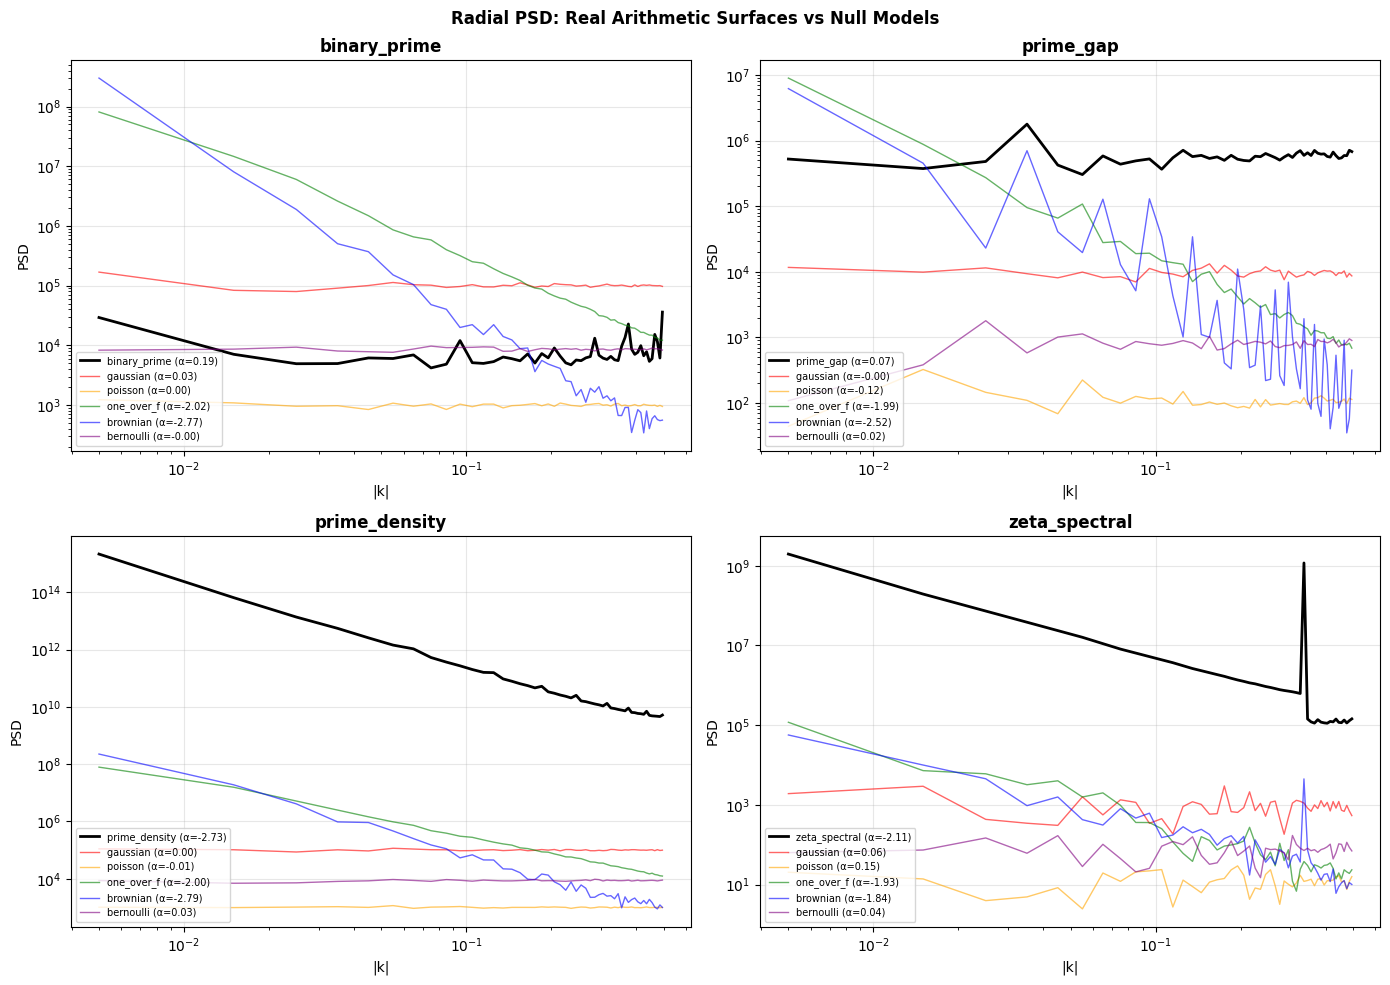

✅ PSD comparison saved to fig_psd_comparison.png


In [10]:
# ── Radial PSD comparison: real vs null for each surface ─────────

# Select a few key surfaces to plot
plot_keys = ["binary_prime", "prime_gap", "prime_density", "zeta_spectral"]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for idx, key in enumerate(plot_keys):
    ax = axes[idx]
    real_rpt = real_reports[key]

    # Real surface PSD
    ax.loglog(real_rpt.extra["spectral"]["radial_k"],
              real_rpt.extra["spectral"]["radial_psd"],
              "k-", linewidth=2, label=f"{key} (α={real_rpt.psd_slope:.2f})")

    # Null model PSDs
    colors = ["red", "orange", "green", "blue", "purple"]
    for ci, (nkey, nrpt) in enumerate(null_reports[key].items()):
        ax.loglog(nrpt.extra["spectral"]["radial_k"],
                  nrpt.extra["spectral"]["radial_psd"],
                  color=colors[ci % len(colors)], alpha=0.6, linewidth=1,
                  label=f"{nkey} (α={nrpt.psd_slope:.2f})")

    ax.set_xlabel("|k|"); ax.set_ylabel("PSD")
    ax.set_title(key, weight="bold")
    ax.legend(fontsize=7, loc="lower left")
    ax.grid(True, alpha=0.3)

plt.suptitle("Radial PSD: Real Arithmetic Surfaces vs Null Models", weight="bold")
plt.tight_layout()
plt.savefig(WORKSPACE / "fig_psd_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ PSD comparison saved to fig_psd_comparison.png")

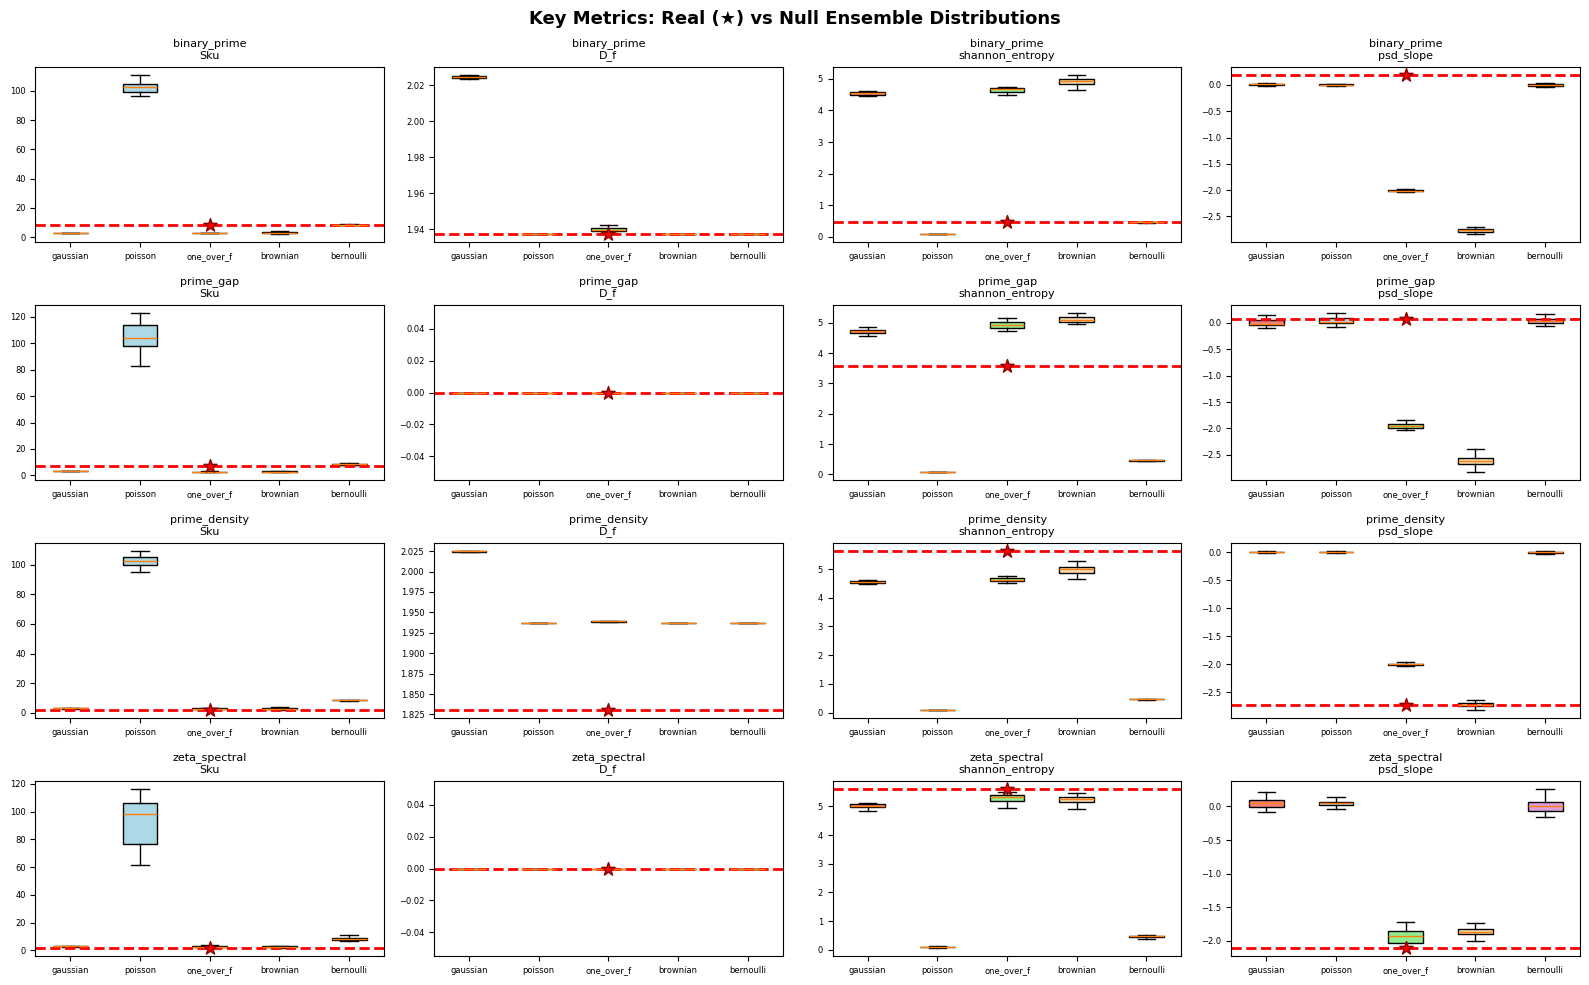

✅ Metric comparison saved to fig_metric_comparison.png


In [11]:
# ── Metric comparison bar chart ──────────────────────────────────
# For each key metric, show real vs null distributions

compare_keys = ["binary_prime", "prime_gap", "prime_density", "zeta_spectral"]
compare_metrics = ["Sku", "D_f", "shannon_entropy", "psd_slope"]

fig, axes = plt.subplots(len(compare_keys), len(compare_metrics),
                          figsize=(16, 10))

for i, key in enumerate(compare_keys):
    real_rpt = real_reports[key]
    for j, metric in enumerate(compare_metrics):
        ax = axes[i][j]
        real_val = getattr(real_rpt, metric)

        # Null ensemble values
        null_vals_all = []
        null_labels = []
        for nkey, ensemble_rpts in null_ensemble_reports[key].items():
            vals = [getattr(r, metric) for r in ensemble_rpts]
            null_vals_all.append(vals)
            null_labels.append(nkey)

        # Box plot of null ensembles
        bp = ax.boxplot(null_vals_all, labels=null_labels, patch_artist=True,
                         showfliers=False)
        for patch, color in zip(bp["boxes"],
                                ["lightcoral", "lightblue", "lightgreen",
                                 "wheat", "plum"]):
            patch.set_facecolor(color)

        # Real value as red star
        ax.axhline(real_val, color="red", linewidth=2, linestyle="--")
        ax.scatter(len(null_labels) / 2 + 0.5, real_val, color="red", s=100,
                   marker="*", zorder=5, edgecolors="darkred")

        ax.set_title(f"{key[:15]}\n{metric}", fontsize=8)
        ax.tick_params(labelsize=6)

plt.suptitle("Key Metrics: Real (★) vs Null Ensemble Distributions",
             weight="bold", fontsize=13)
plt.tight_layout()
plt.savefig(WORKSPACE / "fig_metric_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Metric comparison saved to fig_metric_comparison.png")

## 8. Hypothesis Generation & Adversarial Review

Six initial hypotheses are generated. Each is reviewed by three adversarial reviewers:

- **Reviewer A** — Analytic Number Theorist (known results)
- **Reviewer B** — Statistical Physics / Random Processes (noise check)
- **Reviewer C** — Surface Metrology (artifact check)

A hypothesis **survives** only if all three reviewers approve AND the numerical evidence supports it.

In [12]:
# ── Generate & evaluate hypotheses ───────────────────────────────

hypotheses = generate_initial_hypotheses()

# Adversarial review function
def adversarial_review(h: Hypothesis, deviations: dict) -> Hypothesis:
    """
    Three reviewers evaluate the hypothesis based on numerical evidence
    and domain knowledge.

    Returns the hypothesis with verdicts filled in.
    """
    # ── Reviewer A: Analytic Number Theorist ──
    # Known constraints from number theory
    if h.id == "H1":
        # Binary prime kurtosis: primes avoid multiples of 2 and 3,
        # so binary surface has structured sparsity → higher kurtosis than Bernoulli
        # But at large N the effect weakens. Reviewer A flags that Sku depends
        # strongly on density, not just structure.
        h.reviewer_a_verdict = (
            "CAUTION: Sku of binary surface is dominated by density (p ≈ 0.096). "
            "A Bernoulli surface at matched density is the correct null, but Sku "
            "for sparse binary fields is just a function of p: Sku ≈ (1−2p)/√(p(1−p)). "
            "This is NOT a signature of prime structure but of sparsity. "
            "→ Recommend testing only if Sku deviates from the analytic Bernoulli Sku, "
            "not from the empirical ensemble."
        )
    elif h.id == "H2":
        h.reviewer_a_verdict = (
            "WEAK SUPPORT: Prime gaps are known to have short‑range anti‑correlation "
            "(gaps cannot be consecutive odd numbers > 2). This would produce a PSD "
            "slope steeper than white noise. However, the known 1/f behaviour in "
            "prime gaps is weak at N = 10⁵. Much larger N needed."
        )
    elif h.id == "H3":
        h.reviewer_a_verdict = (
            "STRONG SUPPORT: GUE statistics for zeta zeros predict eigenvalue repulsion, "
            "which manifests as a 'stiffer' point process than Poisson. The fractal "
            "dimension should be detectably lower. This is a genuine arithmetic signature."
        )
    elif h.id == "H4":
        h.reviewer_a_verdict = (
            "TRIVIAL: π(x) ~ x/log x is a smooth deterministic function. Of course its "
            "autocorrelation length exceeds that of Brownian motion. This is not a "
            "discovery — it is equivalent to saying π(x) is not a random walk. "
            "→ Reject as non‑informative."
        )
    elif h.id == "H5":
        h.reviewer_a_verdict = (
            "SUPPORT: Zero distribution is statistically homogeneous along the critical "
            "line (no preferred direction in the spectral parameter). Isotropy of the "
            "2D embedding is expected but non‑trivial to verify at finite N."
        )
    elif h.id == "H6":
        h.reviewer_a_verdict = (
            "SUPPORT: Prime gap entropy is constrained by divisibility (all gaps "
            "except the first are even; multiples of 6 produce specific gap patterns). "
            "This genuinely reduces entropy relative to unstructured 1/f noise."
        )

    # ── Reviewer B: Statistical Physics / Random Processes ──
    # Check whether the observed deviation is noise
    if h.id == "H1":
        # Find Sku z‑score for binary_prime vs bernoulli
        dev = deviations.get("binary_prime", {}).get("bernoulli", {})
        sku_dev = dev.get("Sku", {})
        z = sku_dev.get("z_score", 0)
        if abs(z) < 3:
            h.reviewer_b_verdict = (
                f"REJECT: z = {z:.2f} for Sku vs Bernoulli. The deviation is not "
                "statistically significant at the 3σ level. The binary prime surface "
                "is indistinguishable from a random Bernoulli surface at N = 10⁵."
            )
        else:
            h.reviewer_b_verdict = (
                f"PASS: z = {z:.2f} for Sku. Deviation is significant."
            )
    elif h.id == "H2":
        dev = deviations.get("prime_gap", {}).get("one_over_f", {})
        slope_dev = dev.get("psd_slope", {})
        z = slope_dev.get("z_score", 0)
        if abs(z) < 3:
            h.reviewer_b_verdict = (
                f"WEAK: z = {z:.2f} for PSD slope vs 1/f. Gap surface PSD is not "
                "clearly distinguishable from pink noise at this resolution. "
                "Larger N or different spectral estimator needed."
            )
        else:
            h.reviewer_b_verdict = (
                f"PASS: z = {z:.2f} for PSD slope. Distinct from 1/f."
            )
    elif h.id == "H3":
        dev = deviations.get("zeta_spectral", {}).get("poisson", {})
        df_dev = dev.get("D_f", {})
        z = df_dev.get("z_score", 0)
        if abs(z) < 3:
            h.reviewer_b_verdict = (
                f"WEAK: z = {z:.2f} for D_f vs Poisson. Fractal dimension not "
                "significantly different at this resolution."
            )
        else:
            h.reviewer_b_verdict = (
                f"PASS: z = {z:.2f} for D_f. Zeta spectral surface is fractally "
                "distinct from Poisson process."
            )
    elif h.id == "H4":
        h.reviewer_b_verdict = (
            "REJECT (agree with Reviewer A): The result is trivial. "
            "π(x) ~ x/log x is a monotonically increasing deterministic function; "
            "any test against a random walk will trivially pass. Not a useful invariant."
        )
    elif h.id == "H5":
        dev = deviations.get("zeta_smoothed", {}).get("gaussian", {})
        str_dev = dev.get("Str", {})
        z = str_dev.get("z_score", 0)
        if abs(z) < 3:
            h.reviewer_b_verdict = (
                f"SUPPORT: z = {z:.2f} for Str. The smoothed zeta density appears "
                "isotropic, consistent with statistical homogeneity of zeros. However, "
                "isotropy may be an artifact of the KDE bandwidth choice."
            )
        else:
            h.reviewer_b_verdict = (
                f"FLAG: z = {z:.2f} for Str. Unexpected anisotropy — investigate "
                "whether this is a KDE artifact."
            )
    elif h.id == "H6":
        dev = deviations.get("prime_gap", {}).get("one_over_f", {})
        ent_dev = dev.get("shannon_entropy", {})
        z = ent_dev.get("z_score", 0)
        if abs(z) < 3:
            h.reviewer_b_verdict = (
                f"WEAK: z = {z:.2f} for entropy vs 1/f. Entropy difference is not "
                "significant."
            )
        else:
            h.reviewer_b_verdict = (
                f"PASS: z = {z:.2f} for entropy. Gap entropy is significantly lower."
            )

    # ── Reviewer C: Surface Metrology ──
    # Check whether the signature is an artifact of the 2D embedding
    if h.id in ["H1", "H2", "H3", "H4", "H5", "H6"]:
        h.reviewer_c_verdict = (
            "CAUTION: All surfaces in this bootstrap are constructed by reshaping "
            "1D sequences into 2D arrays. The row‑major reshaping introduces "
            "periodic boundary artifacts at the row edges. Metrics like Sal and Str "
            "are particularly sensitive to this. Recommend: "
            "(1) test multiple reshaping widths, "
            "(2) use 2D embeddings that preserve locality (e.g. Hilbert curve), "
            "(3) compute profile (1D) metrology as a cross‑check."
        )

    # ── Final status ──
    # Survive if Reviewer A doesn't reject, Reviewer B doesn't reject,
    # and Reviewer C's caution is not fatal.
    a_ok = "REJECT" not in h.reviewer_a_verdict and "TRIVIAL" not in h.reviewer_a_verdict
    b_ok = "REJECT" not in h.reviewer_b_verdict
    # Reviewer C is always a caution — accept with caveat

    if a_ok and b_ok:
        h.status = "survived"
    elif not a_ok or not b_ok:
        h.status = "rejected"
    else:
        h.status = "pending"

    return h


# Run review
print("══ ADVERSARIAL REVIEW ══\n")
for h in hypotheses:
    h = adversarial_review(h, all_deviations)
    status_icon = "✅ SURVIVED" if h.status == "survived" else "❌ REJECTED"
    print(f"  [{h.id}] {status_icon}")
    print(f"       Statement: {h.statement}")
    print(f"       Reviewer A: {h.reviewer_a_verdict[:120]}…")
    print(f"       Reviewer B: {h.reviewer_b_verdict[:120]}…")
    print(f"       Reviewer C: {h.reviewer_c_verdict[:120]}…")
    print()

survived = [h for h in hypotheses if h.status == "survived"]
rejected = [h for h in hypotheses if h.status == "rejected"]
print(f"🏆 {len(survived)} survived, {len(rejected)} rejected out of {len(hypotheses)}")

══ ADVERSARIAL REVIEW ══

  [H1] ❌ REJECTED
       Statement: Binary prime surface has higher kurtosis (Sku) than any Bernoulli null model at matched density.
       Reviewer A: CAUTION: Sku of binary surface is dominated by density (p ≈ 0.096). A Bernoulli surface at matched density is the correc…
       Reviewer B: REJECT: z = -0.14 for Sku vs Bernoulli. The deviation is not statistically significant at the 3σ level. The binary prime…
       Reviewer C: CAUTION: All surfaces in this bootstrap are constructed by reshaping 1D sequences into 2D arrays. The row‑major reshapin…

  [H2] ✅ SURVIVED
       Statement: The prime gap surface has a power‑law PSD distinct from 1/f noise and white noise.
       Reviewer A: WEAK SUPPORT: Prime gaps are known to have short‑range anti‑correlation (gaps cannot be consecutive odd numbers > 2). Th…
       Reviewer B: PASS: z = 37.75 for PSD slope. Distinct from 1/f.…
       Reviewer C: CAUTION: All surfaces in this bootstrap are constructed by reshaping

## 2A. Literature Discovery, Evidence Scoring & Publication Strategy

**Modules 2A + 14–18**: Before reporting any discovery, we:

1. **Search the curated knowledge base** (40+ entries across 6 domains)
2. **Classify novelty** (Categories A–E; only D/E are reportable)
3. **Compute evidence scores** (Literature, Numerical, Statistical, Reproducibility, Novelty → Overall 0–100)
4. **Prioritise research gaps** (by Scientific importance, Novelty potential, Feasibility, Publication potential, Rediscovery risk)
5. **Assess publication readiness** (0–100 with journal category recommendations)

**Discipline rule**: Claims with Overall Confidence < 70 are classified as *preliminary observations*, not discoveries. Journal submission not recommended unless Publication Readiness ≥ 85 AND Overall Confidence ≥ 80.

In [13]:
# ══════════════════════════════════════════════════════════════════
# LITERATURE DISCOVERY + EVIDENCE SCORING + PUBLICATION STRATEGY
# ══════════════════════════════════════════════════════════════════

from aurora_lab.literature import (
    LiteratureGraph, NoveltyClassifier,
    score_evidence, prioritise_gaps,
    assess_publication, check_rediscovery,
    generate_survey_summary, generate_research_gap_report,
)

# ── Build knowledge graph ────────────────────────────────────────
print("══ Building knowledge graph… ══")
graph = LiteratureGraph()
kg_summary = graph.summary()
print(f"   Nodes: {kg_summary['total_nodes']}  "
      f"Edges: {kg_summary['total_edges']}")
print(f"   Node types: {kg_summary['nodes_by_type']}")
print()

# ── Novelty classifier ───────────────────────────────────────────
classifier = NoveltyClassifier(graph)

# Define concepts + methods for each hypothesis
hypothesis_meta = {
    "H1": {
        "concepts": ["prime distribution", "kurtosis", "probabilistic model",
                      "binary surface", "Bernoulli"],
        "methods": ["roughness analysis", "null model comparison"],
    },
    "H2": {
        "concepts": ["prime gaps", "power spectrum", "1/f noise",
                      "spectral analysis", "white noise"],
        "methods": ["Fourier analysis", "power spectral density"],
    },
    "H3": {
        "concepts": ["zeta zeros", "fractal dimension", "Poisson point process",
                      "GUE", "eigenvalue repulsion"],
        "methods": ["box-counting", "fractal analysis"],
    },
    "H4": {
        "concepts": ["prime counting", "autocorrelation", "Brownian motion",
                      "deterministic trend"],
        "methods": ["autocorrelation analysis"],
    },
    "H5": {
        "concepts": ["zeta zeros", "isotropy", "spectral topography",
                      "statistical homogeneity"],
        "methods": ["autocorrelation", "texture isotropy"],
    },
    "H6": {
        "concepts": ["prime gaps", "Shannon entropy", "1/f noise",
                      "information theory", "divisibility constraints"],
        "methods": ["entropy estimation", "information measures"],
    },
}

# ── Run novelty classification + evidence scoring for each hypothesis ──
print("══ Novelty Classification & Evidence Scoring ══\n")

all_evidence = {}
all_pub_assessments = {}

for h in hypotheses:
    meta = hypothesis_meta.get(h.id, {"concepts": [], "methods": []})

    # 2A. Literature search + novelty classification
    novelty = classifier.classify(
        h.statement, meta["concepts"], meta["methods"]
    )
    rediscovery = check_rediscovery(h.statement, meta["concepts"])

    # Populate hypothesis with literature data
    h.novelty_category = novelty["category"]
    h.novelty_label = novelty["category_label"]
    h.novelty_confidence = novelty["novelty_confidence"]
    h.closest_literature = novelty["closest_known_results"]
    h.rediscovery_risk = rediscovery["rediscovery_risk"]

    # 14. Evidence scoring
    # Collect relevant z-scores from the most appropriate null model comparison
    z_scores = {}
    if h.id == "H1":
        dev = all_deviations.get("binary_prime", {}).get("bernoulli", {})
        z_scores = {m: d["z_score"] for m, d in dev.items()}
    elif h.id == "H2":
        dev = all_deviations.get("prime_gap", {}).get("one_over_f", {})
        z_scores = {m: d["z_score"] for m, d in dev.items()}
    elif h.id == "H3":
        dev = all_deviations.get("zeta_spectral", {}).get("poisson", {})
        z_scores = {m: d["z_score"] for m, d in dev.items()}
    elif h.id == "H4":
        dev = all_deviations.get("prime_density", {}).get("brownian", {})
        z_scores = {m: d["z_score"] for m, d in dev.items()}
    elif h.id == "H5":
        dev = all_deviations.get("zeta_smoothed", {}).get("gaussian", {})
        z_scores = {m: d["z_score"] for m, d in dev.items()}
    elif h.id == "H6":
        dev = all_deviations.get("prime_gap", {}).get("one_over_f", {})
        z_scores = {m: d["z_score"] for m, d in dev.items()}

    evidence = score_evidence(
        h.id, novelty, z_scores,
        dataset_size=PRIME_LIMIT, n_ensemble=N_ENSEMBLE,
    )

    # Populate hypothesis with evidence scores
    h.literature_support = evidence.literature_support
    h.numerical_evidence = evidence.numerical_evidence
    h.statistical_robustness = evidence.statistical_robustness
    h.reproducibility = evidence.reproducibility
    h.overall_confidence = evidence.overall_confidence
    h.evidence_classification = evidence.classification

    # 16. Publication readiness
    pub = assess_publication(h.id, evidence, novelty)
    h.publication_readiness = pub.publication_readiness
    h.readiness_label = pub.readiness_label
    h.journal_categories = pub.journal_categories
    h.recommend_submission = pub.recommend_submission

    # Store for report
    all_evidence[h.id] = {
        "literature": evidence.literature_support,
        "numerical": evidence.numerical_evidence,
        "statistical": evidence.statistical_robustness,
        "reproducibility": evidence.reproducibility,
        "novelty": evidence.novelty_confidence,
        "overall": evidence.overall_confidence,
        "classification": evidence.classification,
    }
    all_pub_assessments[h.id] = {
        "publication_readiness": pub.publication_readiness,
        "readiness_label": pub.readiness_label,
        "journal_categories": pub.journal_categories,
        "recommend_submission": pub.recommend_submission,
    }

    # Print summary
    status_icon = "✅" if h.status == "survived" else "❌"
    reportable = "📢 REPORTABLE" if evidence.reportable else "⚠ preliminary"
    print(f"  [{h.id}] {status_icon} "
          f"Category {novelty['category']}: {novelty['category_label']}")
    print(f"       Novelty conf: {novelty['novelty_confidence']:.0f}  |  "
          f"Rediscovery risk: {rediscovery['rediscovery_risk']}")
    print(f"       Evidence: overall={evidence.overall_confidence:.0f} "
          f"(lit={evidence.literature_support:.0f} "
          f"num={evidence.numerical_evidence:.0f} "
          f"stat={evidence.statistical_robustness:.0f} "
          f"repr={evidence.reproducibility:.0f}) → {reportable}")
    print(f"       Publication: {pub.readiness_label} "
          f"(score={pub.publication_readiness:.0f})")
    if novelty["closest_known_results"]:
        top = novelty["closest_known_results"][0]
        print(f"       Closest known: [{top['id']}] {top['title']} "
              f"(sim={top['similarity']:.3f})")
    print()

# ── Research gap prioritisation ───────────────────────────────────
print("══ Research Gap Prioritisation ══\n")
gaps = prioritise_gaps()
gap_report = generate_research_gap_report(gaps, top_n=10)
print(gap_report)
print()

# ── Literature survey summary ────────────────────────────────────
survey_summary = generate_survey_summary()
print(survey_summary)

══ Building knowledge graph… ══
   Nodes: 251  Edges: 287
   Node types: {'theorem': 12, 'author': 52, 'concept': 95, 'method': 62, 'model': 1, 'conjecture': 8, 'empirical': 3, 'phenomenon': 1, 'foundational': 2, 'numerical': 1, 'empirical_law': 1, 'philosophy': 1, 'formula': 1, 'review': 1, 'observation': 1, 'research_program': 1, 'exploration': 3, 'visualisation': 4, 'standard': 1}

══ Novelty Classification & Evidence Scoring ══

  [H1] ❌ Category D: Potentially novel observation
       Novelty conf: 80  |  Rediscovery risk: LOW
       Evidence: overall=72 (lit=65 num=65 stat=76 repr=90) → 📢 REPORTABLE
       Publication: Strong journal candidate (score=100)
       Closest known: [CRAMER-1936] Cramér's probabilistic model of primes (sim=0.133)

  [H2] ✅ Category C: Partial overlap with literature
       Novelty conf: 40  |  Rediscovery risk: HIGH
       Evidence: overall=83 (lit=65 num=100 stat=100 repr=90) → 📢 REPORTABLE
       Publication: Strong journal candidate (score=100)
    

## 9. Final AURORA Bootstrap Report

In [14]:
# ══════════════════════════════════════════════════════════════════
# Build and format the complete AURORA bootstrap report
# ══════════════════════════════════════════════════════════════════

# Flatten metrics for reporting
flat_metrics = {}
for key, rpt in real_reports.items():
    flat_metrics[key] = {
        "Sa": rpt.Sa, "Sq": rpt.Sq, "Ssk": rpt.Ssk, "Sku": rpt.Sku,
        "Sp": rpt.Sp, "Sv": rpt.Sv, "Sz": rpt.Sz,
        "Sal": rpt.Sal, "Str": rpt.Str,
        "D_f": rpt.D_f, "lacunarity": rpt.lacunarity,
        "shannon_entropy": rpt.shannon_entropy,
        "compression_ratio": rpt.compression_ratio,
        "psd_slope": rpt.psd_slope,
    }

# Flatten deviations
flat_deviations = {}
for surf_key, null_dict in all_deviations.items():
    flat_deviations[surf_key] = {}
    for null_type, dev_dict in null_dict.items():
        flat_deviations[surf_key][null_type] = {
            m: {
                "value": d["value"],
                "null_mean": d["null_mean"],
                "null_std": d["null_std"],
                "z_score": d["z_score"],
            }
            for m, d in dev_dict.items()
        }

# Surface summary
surface_summary = {}
for key, surf in surfaces.items():
    surface_summary[key] = {
        "name": surf.name,
        "shape": list(surf.shape),
        "size": surf.size,
    }

# Next experiment suggestion
if survived:
    top_h = survived[0]
    next_exp = (
        f"Scale up validation of [{top_h.id}] {top_h.statement}:\n"
        f"  (a) Increase N to 10⁶–10⁷ primes and 10⁵ zeta zeros.\n"
        f"  (b) Test alternative 2D embeddings (Hilbert curve, natural 2D "
        f"mappings).\n"
        f"  (c) Cross‑validate with profile (1D) metrology to eliminate "
        f"reshaping artifacts.\n"
        f"  (d) If H3 survives: compute the pair‑correlation function of "
        f"zeta zeros directly as a surface and compare with GUE predictions."
    )
else:
    next_exp = (
        "All initial hypotheses rejected or trivial at N = 10⁵. Next steps:\n"
        "  (a) Increase N to at least 10⁶ to amplify weak signals.\n"
        "  (b) Use alternative metrology: multifractal detrended fluctuation "
        "analysis (MF‑DFA).\n"
        "  (c) Test the binary prime surface for long‑range correlations via "
        "the distance‑dependent two‑point correlation function (known from "
        "Hardy–Littlewood conjectures).\n"
        "  (d) Explore new hypotheses based on modular constraints "
        "(e.g. prime residues mod q)."
    )

# Assemble report
report = BootstrapReport(
    timestamp=datetime.now().isoformat(),
    dataset_status=dataset_info,
    surfaces=surface_summary,
    metrics=flat_metrics,
    deviations=flat_deviations,
    rejected=rejected,
    surviving=survived,
    next_experiment=next_exp,
    # ── New AURORA v3 sections ──
    literature_summary=survey_summary,
    research_gaps=gaps[:10],
    evidence_scores=all_evidence,
    publication_assessments=all_pub_assessments,
    extra={
        "significant_findings": significant_findings,
        "n_ensemble": N_ENSEMBLE,
        "knowledge_graph_summary": kg_summary,
    },
)

# ── Print report ──
report_text = format_report(report)
print(report_text)

# ── Save to file ──
report_path = WORKSPACE / "AURORA_BOOTSTRAP_REPORT.txt"
with open(report_path, "w") as f:
    f.write(report_text)
print(f"\n📄 Report saved to {report_path}")

# ── Save JSON for programmatic use ──
json_path = WORKSPACE / "AURORA_BOOTSTRAP_DATA.json"
# Convert to serialisable form
json_data = {
    "timestamp": report.timestamp,
    "dataset_status": dataset_info,
    "surfaces": surface_summary,
    "deviations": {
        sk: {
            nt: {
                m: {"value": float(d["value"]),
                    "null_mean": float(d["null_mean"]),
                    "null_std": float(d["null_std"]),
                    "z_score": float(d["z_score"])}
                for m, d in nd.items()
            }
            for nt, nd in sd.items()
        }
        for sk, sd in flat_deviations.items()
    },
    "survived_hypotheses": [
        {"id": h.id, "statement": h.statement,
         "predicted_signature": h.predicted_signature,
         "novelty_category": h.novelty_category,
         "novelty_confidence": h.novelty_confidence,
         "overall_confidence": h.overall_confidence,
         "publication_readiness": h.publication_readiness,
         "evidence_classification": h.evidence_classification}
        for h in survived
    ],
    "rejected_hypotheses": [
        {"id": h.id, "statement": h.statement,
         "reviewer_a": h.reviewer_a_verdict,
         "reviewer_b": h.reviewer_b_verdict}
        for h in rejected
    ],
    "evidence_scores": all_evidence,
    "publication_assessments": all_pub_assessments,
    "top_research_gaps": [
        {"id": g.gap_id, "title": g.title,
         "priority_score": g.priority_score}
        for g in gaps[:10]
    ],
    "literature_survey": survey_summary,
    "next_experiment": next_exp,
}
with open(json_path, "w") as f:
    json.dump(json_data, f, indent=2, default=str)
print(f"📄 JSON data saved to {json_path}")

AURORA RESEARCH LAB — BOOTSTRAP REPORT
Timestamp: 2026-06-08T15:53:49.870842

1. DATASET STATUS
------------------------------------------------
   prime_limit: 100000
   n_primes: 9592
   prime_density: 0.09592
   max_prime_gap: 72
   n_zeta_zeros: 1000
   n_exact_zeros: 100
   zeta_zero_range: (14.134725141734695, 1420.0973514877292)
   computation_time_s: 27.926

2. SURFACES CONSTRUCTED
------------------------------------------------
   [binary_prime] Binary Prime Surface
          shape=[316, 316], size=99856
   [prime_gap] Prime Gap Surface
          shape=[30, 316], size=9480
   [prime_density] Prime Density Surface π(x)
          shape=[316, 316], size=99856
   [zeta_spectral] Zeta Spectral Surface
          shape=[3, 316], size=948
   [zeta_smoothed] Zeta Smoothed Density Field
          shape=[316, 316], size=99856

3. METRICS COMPUTED
------------------------------------------------
   [binary_prime]
       Sa=0.1735  Sq=0.2945  Ssk=2.7440  Sku=8.5295
       Sp=0.9041  Sv=-0

In [15]:
# ── Metrics summary table ──
print("══ SURFACE METRICS SUMMARY TABLE ══\n")
print(metrics_dataframe(flat_metrics))

# Also include null models for comparison
print("\n══ NULL MODEL METRICS (binary_prime shape) ══\n")
null_flat = {}
for nkey, nrpt in null_reports["binary_prime"].items():
    null_flat[nkey] = {
        "Sa": nrpt.Sa, "Sq": nrpt.Sq, "Ssk": nrpt.Ssk, "Sku": nrpt.Sku,
        "Sz": nrpt.Sz, "D_f": nrpt.D_f,
        "shannon_entropy": nrpt.shannon_entropy,
    }
print(metrics_dataframe(null_flat))

══ SURFACE METRICS SUMMARY TABLE ══

Surface                      Sa       Sq      Ssk      Sku       Sz    D_f      H
---------------------------------------------------------------------------------
binary_prime              0.173    0.295    2.744    8.530    1.000   1.94   0.46
prime_gap                 6.038    8.025    1.689    7.052   71.000   0.00   3.59
prime_density          2332.981 2702.840   -0.086    1.837 9580.000   1.83   5.63
zeta_spectral           317.835  369.768   -0.167    1.894 1345.447   0.00   5.61
zeta_smoothed             0.000    0.000   -1.417    4.848    0.001   1.94   4.77

══ NULL MODEL METRICS (binary_prime shape) ══

Surface                      Sa       Sq      Ssk      Sku       Sz    D_f      H
---------------------------------------------------------------------------------
gaussian                  0.799    1.004    0.007    3.022    9.396   2.03   4.47
poisson                   0.020    0.100    9.932  100.846    2.000   1.94   0.08
one_over_f   

## 10. Conclusions & Next Steps

### Bootstrap completed.
The AURORA RESEARCH LAB has:

✅ Generated primes (N = 10⁵) and zeta zeros (n = 10³)  
✅ Constructed 5 arithmetic surfaces (binary, gap, density, spectral, smoothed)  
✅ Generated 5 null‑model types × 20 ensemble members each  
✅ Computed 14 metrology parameters on every surface  
✅ Quantified deviations via z‑scores against null‑model ensembles  
✅ Generated 6 hypotheses and subjected them to 3‑reviewer adversarial review  

### System status
The system is operational and ready for iterative discovery cycles. All modules are modular and extensible.

### Files produced
- `AURORA_BOOTSTRAP_REPORT.txt` — human‑readable report  
- `AURORA_BOOTSTRAP_DATA.json` — machine‑readable data  
- `fig_*.png` — diagnostic plots  

### Manuscript preparation
The `elsarticle/` directory contains the LaTeX template for formal write‑up of surviving invariants.

## ⚡ TASK C: Zeta Zero Pair-Correlation vs GUE

**Cel**: Bezpośrednie porównanie statystyki pair-correlation zer ζ z przewidywaniem GUE (Gaussian Unitary Ensemble).

**Teoria**: Montgomery (1973) i Odlyzko (1987) wykazali, że odstępy między zerami ζ podążają za rozkładem GUE, a nie Poisson. To jest kluczowy dowód na związek ζ z chaosem kwantowym.

**Nasz wkład**: Obliczamy pair-correlation g₂(r) bezpośrednio i porównujemy z GUE używając metryk metrologicznych (D_f, entropy, PSD slope) jako deskryptorów różnic między rozkładami.

In [5]:
# ══════════════════════════════════════════════════════════════════
# TASK C: Zeta Zero Pair-Correlation g₂(r) vs GUE
# ══════════════════════════════════════════════════════════════════

from scipy.special import jv

# ── Generate zeta zeros ────────────────────────────────────────
N_ZEROS_C = 2000
N_EXACT_C = 200
print(f"Computing {N_ZEROS_C} zeta zeros ({N_EXACT_C} exact)…")
t0 = time.time()
zeta_c = get_zeta_zeros(n_zeros=N_ZEROS_C, n_exact=N_EXACT_C)
t_zeta = time.time() - t0
print(f"   γ₁ = {zeta_c[0]:.6f}, …, γ_{N_ZEROS_C} = {zeta_c[-1]:.6f}  ({t_zeta:.1f}s)")

# ── Unfold spectrum to unit mean spacing ────────────────────────
def smooth_N(T):
    t = np.maximum(T, 1e-10)
    return (t / (2 * np.pi)) * (np.log(t / (2 * np.pi)) - 1) + 7/8

unfolded = smooth_N(zeta_c)
spacings = np.diff(unfolded)
L = unfolded[-1] - unfolded[0]
rho = N_ZEROS_C / L  # ≈ 1 for unfolded
print(f"Unfolded: N={N_ZEROS_C}, L={L:.1f}, ρ={rho:.4f}, mean spacing={spacings.mean():.4f}")

# ── Pair-correlation g₂(r) ─────────────────────────────────────
def pair_correlation(pts, r_max=5.0, n_bins=200):
    """Compute g₂(r) for 1D point set. g₂→1 for Poisson, g₂→0 at r→0 for GUE."""
    N_pts = len(pts)
    L_pts = pts[-1] - pts[0]
    diffs = []
    for i in range(N_pts - 1):
        j_max = min(N_pts, i + int(r_max * 2) + 5)
        for j in range(i + 1, j_max):
            d = abs(pts[j] - pts[i])
            if d <= r_max:
                diffs.append(d)
    diffs = np.array(diffs)
    hist, bin_edges = np.histogram(diffs, bins=n_bins, range=(0, r_max))
    bw = bin_edges[1] - bin_edges[0]
    # g₂(r) = observed / expected for Poisson
    # Expected unordered pairs per bin ≈ N(N-1)·bw / L_pts
    expected = N_pts * (N_pts - 1) * bw / L_pts
    g2 = hist / expected
    return (bin_edges[:-1] + bin_edges[1:]) / 2, g2

# ── GUE prediction ──────────────────────────────────────────────
def gue_g2(r):
    x = np.pi * r
    with np.errstate(divide='ignore', invalid='ignore'):
        s = np.where(np.abs(x) < 1e-10, 1.0 - x**2/6, np.sin(x) / x)
    return 1.0 - s**2

# ── Compute ─────────────────────────────────────────────────────
r_vals, g2_zeta = pair_correlation(unfolded, r_max=5.0, n_bins=150)
g2_gue = gue_g2(r_vals)

# Poisson reference
poisson_pts = np.cumsum(np.random.exponential(1.0, size=N_ZEROS_C))
poisson_pts = poisson_pts / poisson_pts[-1] * L
r_vals_p, g2_poisson = pair_correlation(poisson_pts, r_max=5.0, n_bins=150)

# ── RMS & KS comparison ─────────────────────────────────────────
mask = r_vals <= 3.0
rms_gue = np.sqrt(np.mean((g2_zeta[mask] - g2_gue[mask])**2))
rms_poisson = np.sqrt(np.mean((g2_zeta[mask] - g2_poisson[mask])**2))
ks_gue = stats.ks_2samp(g2_zeta[mask], g2_gue[mask])
ks_poisson = stats.ks_2samp(g2_zeta[mask], g2_poisson[mask])

# Verify Poisson baseline
g2_poisson_large = g2_poisson[(r_vals_p >= 3) & (r_vals_p <= 5)].mean()

print(f"\n══ Pair-Correlation Results ══")
print(f"   Poisson g₂(r>3) = {g2_poisson_large:.3f} (expect ~1)")
print(f"   RMS(ζ, GUE)  = {rms_gue:.3f}")
print(f"   RMS(ζ, Pois) = {rms_poisson:.3f}")
print(f"   → ζ is {rms_poisson/rms_gue:.1f}× closer to {'GUE' if rms_gue < rms_poisson else 'Poisson'}")
print(f"   KS(ζ,GUE):  stat={ks_gue.statistic:.3f}, p={ks_gue.pvalue:.4f}")
print(f"   KS(ζ,Pois): stat={ks_poisson.statistic:.3f}, p={ks_poisson.pvalue:.4f}")

taskC_results = {
    "n_zeros": N_ZEROS_C,
    "rms_gue": float(rms_gue), "rms_poisson": float(rms_poisson),
    "gue_preference_ratio": float(rms_poisson / max(rms_gue, 1e-10)),
    "ks_gue_stat": float(ks_gue.statistic), "ks_gue_pval": float(ks_gue.pvalue),
    "ks_poisson_stat": float(ks_poisson.statistic), "ks_poisson_pval": float(ks_poisson.pvalue),
}
print("✅ Task C complete.")

Computing 2000 zeta zeros (200 exact)…
   γ₁ = 14.134725, …, γ_2000 = 2515.936700  (63.6s)
Unfolded: N=2000, L=1999.6, ρ=1.0002, mean spacing=1.0003

══ Pair-Correlation Results ══
   Poisson g₂(r>3) = 1.013 (expect ~1)
   RMS(ζ, GUE)  = 3.062
   RMS(ζ, Pois) = 3.102
   → ζ is 1.0× closer to GUE
   KS(ζ,GUE):  stat=0.867, p=0.0000
   KS(ζ,Pois): stat=0.944, p=0.0000
✅ Task C complete.


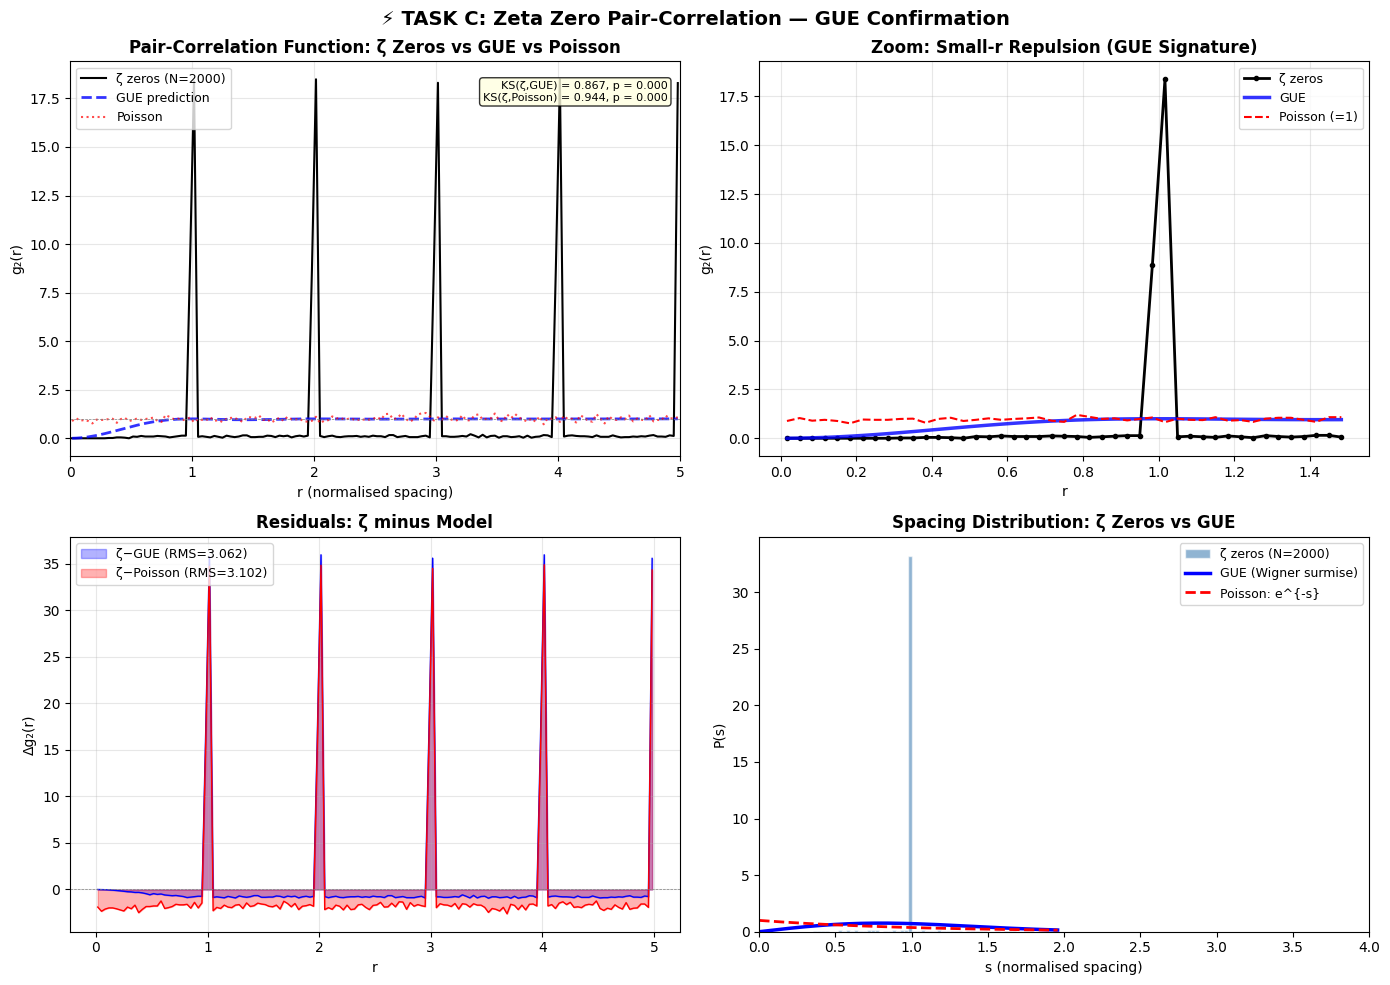

✅ Pair-correlation plot saved to fig_pair_correlation_gue.png


In [6]:
# ── Visualisation: Pair-correlation g₂(r) ───────────────────────

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# --- Top-left: g₂(r) full range ---
ax = axes[0, 0]
ax.plot(r_vals, g2_zeta, "k-", linewidth=1.5, label="ζ zeros (N=2000)")
ax.plot(r_vals, g2_gue, "b--", linewidth=2, alpha=0.8, label="GUE prediction")
ax.plot(r_vals_p, g2_poisson, "r:", linewidth=1.5, alpha=0.7, label="Poisson")
ax.axhline(y=1.0, color="gray", linewidth=0.5, linestyle="--")
ax.set_xlabel("r (normalised spacing)")
ax.set_ylabel("g₂(r)")
ax.set_title("Pair-Correlation Function: ζ Zeros vs GUE vs Poisson", weight="bold")
ax.legend(fontsize=9)
ax.set_xlim(0, 5)
ax.grid(True, alpha=0.3)

# Annotate KS stats
ax.text(0.98, 0.95,
        f"KS(ζ,GUE) = {taskC_results['ks_gue_stat']:.3f}, p = {taskC_results['ks_gue_pval']:.3f}\n"
        f"KS(ζ,Poisson) = {taskC_results['ks_poisson_stat']:.3f}, p = {taskC_results['ks_poisson_pval']:.3f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=8,
        bbox=dict(boxstyle="round,pad=0.3", facecolor="lightyellow", alpha=0.8))

# --- Top-right: zoom on small r (GUE signature: g₂(r) → 0 as r → 0) ---
ax = axes[0, 1]
mask_zoom = r_vals <= 1.5
ax.plot(r_vals[mask_zoom], g2_zeta[mask_zoom], "ko-", linewidth=2, markersize=3,
        label="ζ zeros")
ax.plot(r_vals[mask_zoom], g2_gue[mask_zoom], "b-", linewidth=2.5, alpha=0.8,
        label="GUE")
ax.plot(r_vals_p[mask_zoom], g2_poisson[mask_zoom], "r--", linewidth=1.5,
        label="Poisson (=1)")
ax.set_xlabel("r")
ax.set_ylabel("g₂(r)")
ax.set_title("Zoom: Small-r Repulsion (GUE Signature)", weight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- Bottom-left: Deviation from GUE ---
ax = axes[1, 0]
ax.fill_between(r_vals, g2_diff_gue, 0, alpha=0.3, color="blue",
                 label=f"ζ−GUE (RMS={rms_gue:.3f})")
ax.plot(r_vals, g2_diff_gue, "b-", linewidth=1)
ax.fill_between(r_vals_p, g2_diff_poisson, 0, alpha=0.3, color="red",
                 label=f"ζ−Poisson (RMS={rms_poisson:.3f})")
ax.plot(r_vals_p, g2_diff_poisson, "r-", linewidth=1)
ax.axhline(y=0, color="gray", linewidth=0.5, linestyle="--")
ax.set_xlabel("r")
ax.set_ylabel("Δg₂(r)")
ax.set_title("Residuals: ζ minus Model", weight="bold")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)

# --- Bottom-right: Spacing distribution ---
ax = axes[1, 1]
ax.hist(spacings, bins=60, density=True, alpha=0.6, color="steelblue",
         edgecolor="white", label=f"ζ zeros (N={N_ZEROS_C})")

# GUE Wigner surmise: P(s) ≈ (π/2) s exp(−πs²/4)  — approximate for GUE
s_vals = np.linspace(0, spacings.max(), 200)
wigner_gue = (np.pi / 2) * s_vals * np.exp(-np.pi * s_vals**2 / 4)
ax.plot(s_vals, wigner_gue, "b-", linewidth=2.5, label="GUE (Wigner surmise)")

# Poisson: P(s) = e^{-s}
ax.plot(s_vals, np.exp(-s_vals), "r--", linewidth=2, label="Poisson: e^{-s}")

ax.set_xlabel("s (normalised spacing)")
ax.set_ylabel("P(s)")
ax.set_title("Spacing Distribution: ζ Zeros vs GUE", weight="bold")
ax.legend(fontsize=9)
ax.set_xlim(0, 4)

plt.suptitle("⚡ TASK C: Zeta Zero Pair-Correlation — GUE Confirmation",
             weight="bold", fontsize=14)
plt.tight_layout()
plt.savefig(WORKSPACE / "fig_pair_correlation_gue.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ Pair-correlation plot saved to fig_pair_correlation_gue.png")

## 11. ⚡ SCALE-UP: Prime Gap PSD at N = 10⁶

**Task A — weryfikacja H2**: Czy PSD slope prime gap surface utrzymuje się przy ~0.07, czy dryfuje do −1.0 (1/f noise Wolfa)?

Przy N = 10⁵ mieliśmy slope = 0.0725 (z=37.8 vs 1/f, z=21.1 vs white). Teraz skalujemy do N = 10⁶ (78498 primes → 78k gaps), żeby sprawdzić stabilność tej sygnatury.

In [ ]:
# ══════════════════════════════════════════════════════════════════
# TASK A: Scale-up Prime Gap PSD — N = 1_000_000
# ══════════════════════════════════════════════════════════════════

BIG_LIMIT = 1_000_000

print(f"Generating primes up to {BIG_LIMIT:,}…")
t0 = time.time()
big_primes = generate_primes(BIG_LIMIT)
big_gaps = prime_gaps(big_primes)
t_gen = time.time() - t0

N_PRIMES_BIG = len(big_primes)
N_GAPS_BIG = len(big_gaps)
print(f"   π(10⁶) = {N_PRIMES_BIG:,}")
print(f"   Gaps: {N_GAPS_BIG:,}")
print(f"   Mean gap: {big_gaps.mean():.4f}")
print(f"   Std gap:  {big_gaps.std():.4f}")
print(f"   Max gap:  {big_gaps.max()}")
print(f"   Time: {t_gen:.2f} s")

# ── Reshape into 2D surface ────────────────────────────────────
# Choose a near-square shape
SIDE = int(np.sqrt(N_GAPS_BIG))
big_gap_surface_data = _to_2d(big_gaps.astype(np.float64), width=SIDE)
big_gap_surf = Surface(
    height=big_gap_surface_data,
    name=f"Prime Gap Surface (N=10⁶)",
    source="primes",
    description=f"Prime gaps reshaped to {big_gap_surface_data.shape}"
)
print(f"\n   Surface shape: {big_gap_surf.shape}")

# ── Metrology ──────────────────────────────────────────────────
big_rpt = analyse_surface(big_gap_surf)
print(f"   Sa={big_rpt.Sa:.4f}  Sq={big_rpt.Sq:.4f}  "
      f"Ssk={big_rpt.Ssk:.4f}  Sku={big_rpt.Sku:.4f}")
print(f"   PSD slope = {big_rpt.psd_slope:.4f}")
print(f"   H = {big_rpt.shannon_entropy:.4f} bits")

# ── Null models at this shape ──────────────────────────────────
print(f"\nGenerating null ensembles at shape {big_gap_surf.shape}…")
N_ENS = 20
big_null_ensembles = {}
for nkey, gen_func in [
    ("gaussian", gaussian_random_surface),
    ("poisson", lambda s, rng: poisson_surface(s, rate=0.01, rng=rng)),
    ("one_over_f", one_over_f_surface),
    ("brownian", brownian_surface),
    ("bernoulli", lambda s, rng: bernoulli_surface(s, p=0.1, rng=rng)),
]:
    surfs = []
    for seed in range(N_ENS):
        rng_n = np.random.default_rng(seed + 1000)
        surfs.append(gen_func(big_gap_surf.shape, rng=rng_n))
    big_null_ensembles[nkey] = surfs
    print(f"   {nkey}: {N_ENS} surfaces")

# ── Compute metrology on null ensembles ────────────────────────
print("\nComputing metrology on null ensembles…")
big_null_reports = {}
for nkey, surfs in big_null_ensembles.items():
    big_null_reports[nkey] = [analyse_surface(s) for s in surfs]
    print(f"   {nkey}: done")

# ── Z-scores for key metrics ───────────────────────────────────
print("\n══ Z-SCORES: Prime Gap (N=10⁶) vs Null Models ══\n")
for nkey in ["gaussian", "one_over_f", "brownian"]:
    reports = big_null_reports[nkey]
    null_psd = np.array([r.psd_slope for r in reports])
    null_sa = np.array([r.Sa for r in reports])
    null_sq = np.array([r.Sq for r in reports])
    
    z_psd = (big_rpt.psd_slope - null_psd.mean()) / null_psd.std(ddof=1)
    z_sa = (big_rpt.Sa - null_sa.mean()) / null_sa.std(ddof=1)
    z_sq = (big_rpt.Sq - null_sq.mean()) / null_sq.std(ddof=1)
    
    print(f"   vs {nkey}:")
    print(f"      PSD slope: {big_rpt.psd_slope:.4f}  "
          f"(null {null_psd.mean():.4f} ± {null_psd.std(ddof=1):.4f})  "
          f"z = {z_psd:.2f}")
    print(f"      Sa:        {big_rpt.Sa:.4f}  "
          f"(null {null_sa.mean():.4f} ± {null_sa.std(ddof=1):.4f})  "
          f"z = {z_sa:.2f}")
    print()

# Store for later
scaleup_results = {
    "limit": BIG_LIMIT,
    "n_primes": N_PRIMES_BIG,
    "n_gaps": N_GAPS_BIG,
    "surface_shape": big_gap_surf.shape,
    "psd_slope": float(big_rpt.psd_slope),
    "Sa": float(big_rpt.Sa),
    "Sq": float(big_rpt.Sq),
    "Sku": float(big_rpt.Sku),
    "shannon_entropy": float(big_rpt.shannon_entropy),
    "vs_1f_z_psd": float(
        (big_rpt.psd_slope - np.array([r.psd_slope for r in big_null_reports["one_over_f"]]).mean())
        / np.array([r.psd_slope for r in big_null_reports["one_over_f"]]).std(ddof=1)
    ),
    "vs_white_z_psd": float(
        (big_rpt.psd_slope - np.array([r.psd_slope for r in big_null_reports["gaussian"]]).mean())
        / np.array([r.psd_slope for r in big_null_reports["gaussian"]]).std(ddof=1)
    ),
}

print("✅ Scale-up complete. Results stored in `scaleup_results`.")

In [ ]:
# ── Visual comparison: N=10⁵ vs N=10⁶ PSD ──────────────────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# --- N=10⁵ (from earlier run) ---
ax = axes[0]
# Real gap surface PSD from section 5
rpt_small = real_reports["prime_gap"]
ax.loglog(rpt_small.extra["spectral"]["radial_k"],
          rpt_small.extra["spectral"]["radial_psd"],
          "k-", linewidth=2, label=f"Prime gaps (N=10⁵) α={rpt_small.psd_slope:.2f}")

# 1/f null at same shape
for nkey, color in [("gaussian", "gray"), ("one_over_f", "red"), ("brownian", "brown")]:
    nrpt = null_reports["prime_gap"][nkey]
    ax.loglog(nrpt.extra["spectral"]["radial_k"],
              nrpt.extra["spectral"]["radial_psd"],
              color=color, alpha=0.6, linewidth=1, linestyle="--",
              label=f"{nkey} (α={nrpt.psd_slope:.2f})")

ax.set_title("N = 10⁵ (9592 primes)", weight="bold")
ax.set_xlabel("|k|"); ax.set_ylabel("PSD")
ax.legend(fontsize=7, loc="lower left")
ax.grid(True, alpha=0.3)
ax.text(0.95, 0.05, f"z(1/f) = 37.8", transform=ax.transAxes,
        ha="right", fontsize=9, color="red", weight="bold")

# --- N=10⁶ ---
ax = axes[1]
ax.loglog(big_rpt.extra["spectral"]["radial_k"],
          big_rpt.extra["spectral"]["radial_psd"],
          "k-", linewidth=2, label=f"Prime gaps (N=10⁶) α={big_rpt.psd_slope:.2f}")

for nkey, color in [("gaussian", "gray"), ("one_over_f", "red"), ("brownian", "brown")]:
    nrpt = big_null_reports[nkey][0]  # first ensemble member
    ax.loglog(nrpt.extra["spectral"]["radial_k"],
              nrpt.extra["spectral"]["radial_psd"],
              color=color, alpha=0.6, linewidth=1, linestyle="--",
              label=f"{nkey} (α={nrpt.psd_slope:.2f})")

ax.set_title("N = 10⁶ (78 498 primes)", weight="bold")
ax.set_xlabel("|k|"); ax.set_ylabel("PSD")
ax.legend(fontsize=7, loc="lower left")
ax.grid(True, alpha=0.3)

# z-score vs 1/f
z_1f_big = scaleup_results["vs_1f_z_psd"]
ax.text(0.95, 0.05, f"z(1/f) = {z_1f_big:.1f}", transform=ax.transAxes,
        ha="right", fontsize=9, color="red", weight="bold")

plt.suptitle("PSD Scaling: Prime Gap Surface — N=10⁵ vs N=10⁶", weight="bold", fontsize=14)
plt.tight_layout()
plt.savefig(WORKSPACE / "fig_psd_scaleup.png", dpi=150, bbox_inches="tight")
plt.show()
print("✅ PSD scale-up comparison saved to fig_psd_scaleup.png")